# ✈️ Flight Delay Analysis – EDA

## Project Overview

This project focuses on Exploratory Data Analysis (EDA) of flight delay data.

The main objective is to understand flight delays, identify missing values, detect outliers, and explore different factors affecting flight delays.

## Literature Review

Previous research has shown that flight delays are influenced by several factors, including airline operations, weather conditions, and air traffic control.

Wu et al. (2018) studied how flight delays propagate to subsequent flights and highlighted the importance of proper flight scheduling.

Giannikas et al. (2022) used a data-driven approach to study the causes and impact of delay propagation in airline operations.

These studies provide a foundation for the present project, which uses Exploratory Data Analysis (EDA) to identify flight delay patterns, major delay causes, and relationships between different flight-related variables.

### References

1. Wu, W., et al. (2018). *Comparative Analysis on Propagation Effects of Flight Delays: A Case Study of China Airlines.*
   https://doi.org/10.1155/2018/5236798

2. Giannikas, V., et al. (2022). *A Data-Driven Method to Assess the Causes and Impact of Delay Propagation in Air Transportation Systems.*
   https://doi.org/10.1016/j.trc.2022.103862


## Objectives
- Understand the dataset structure.
- Perform initial data inspection.
- Identify and handle missing values.
- Check duplicate records.
- Detect outliers using boxplots.
- Analyze the distribution of arrival delays.
- Draw meaningful insights from visualizations.

## Dataset Information
- Total Records: 4,821
- Total Columns: 18
- Domain: Flight Delay Analysis



## 1. Importing Libraries and Loading Dataset

First, we import the Pandas library to work with the dataset.

The `read_csv()` function is used to load the flight dataset into a DataFrame.

The `head()` function displays the first five rows to get an initial overview of the data.


In [4]:
import pandas as pd
df = pd.read_csv('flight_modified.csv')
df.head()

,DayOfWeek,Origin_Airport,Scheduled_Departure,Departure_Time,Dep_Delay,Scheduled_Arrival,Arrival_Time,Arrival_Delay,Arr_Del_morethan15,Cancelled,Diverted,Distance,Carrier_Delay,WeatherDelay,NAS_Delay,Security_Delay,Late_Aircraft_Delay,Top_Carriers
0,5,BOS,600,554,18.0,711,707,-4.0,0,0,0,187.0,8.0,0.0,0.0,0,0,1
1,6,NaN,600,554,22.0,711,703,-8.0,0,0,0,187.0,13.0,0.0,NaN,0,0,1
2,1,BOS,600,601,1.0,711,706,NaN,0,0,0,187.0,6.0,NaN,NaN,0,0,1
3,2,BOS,600,556,-4.0,711,709,NaN,0,0,0,187.0,0.0,0.0,0.0,0,0,1
4,3,BOS,600,552,-8.0,711,659,-12.0,0,0,0,NaN,4.0,0.0,0.0,0,0,1



## 2. Understanding the Dataset

In this step, we perform an initial inspection of the dataset to understand its structure, columns, data types, and statistical summary.

- `df.shape` – Displays the total number of rows and columns.
- `df.info()` – Provides information about column names, data types, and non-null values.
- `df.describe()` – Generates statistical summaries such as mean, standard deviation, minimum, maximum, and quartiles for numerical columns.


In [3]:
print(df.shape)

(4821, 18)


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4821 entries, 0 to 4820
Data columns (total 18 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   DayOfWeek            4821 non-null   int64  
 1   Origin_Airport       4629 non-null   object 
 2   Scheduled_Departure  4821 non-null   int64  
 3   Departure_Time       4821 non-null   int64  
 4   Dep_Delay            4561 non-null   float64
 5   Scheduled_Arrival    4821 non-null   int64  
 6   Arrival_Time         4821 non-null   int64  
 7   Arrival_Delay        4438 non-null   float64
 8   Arr_Del_morethan15   4821 non-null   int64  
 9   Cancelled            4821 non-null   int64  
 10  Diverted             4821 non-null   int64  
 11  Distance             4436 non-null   float64
 12  Carrier_Delay        4801 non-null   float64
 13  WeatherDelay         4603 non-null   float64
 14  NAS_Delay            4474 non-null   float64
 15  Security_Delay       4821 non-null   i

In [5]:
print(df.describe())

         DayOfWeek  Scheduled_Departure  Departure_Time    Dep_Delay  \
count  4821.000000          4821.000000     4821.000000  4561.000000   
mean      4.153703          1338.688032     1335.738021    36.030695   
std       2.007099           495.435065      524.024009   120.731783   
min       1.000000            40.000000        1.000000   -20.000000   
25%       2.000000           900.000000      857.000000    -2.000000   
50%       4.000000          1335.000000     1334.000000    11.000000   
75%       6.000000          1725.000000     1751.000000    29.000000   
max       7.000000          2357.000000     2400.000000  1498.000000   

       Scheduled_Arrival  Arrival_Time  Arrival_Delay  Arr_Del_morethan15  \
count        4821.000000   4821.000000    4438.000000         4821.000000   
mean         1502.412777   1468.282099      24.011492            0.322132   
std           562.241023    600.535851     106.182684            0.467342   
min             5.000000      1.000000     


## 3. Checking Missing Values and Duplicate Records

In this step, we check whether the dataset contains missing values or duplicate records.

- `df.isnull().sum()` – Counts the number of missing values in each column.
- `df.duplicated().sum()` – Counts the total number of duplicate rows in the dataset.

Checking missing values and duplicates helps us understand the quality of the dataset before performing further analysis.


In [6]:
df.isnull().sum()

DayOfWeek                0
Origin_Airport         192
Scheduled_Departure      0
Departure_Time           0
Dep_Delay              260
Scheduled_Arrival        0
Arrival_Time             0
Arrival_Delay          383
Arr_Del_morethan15       0
Cancelled                0
Diverted                 0
Distance               385
Carrier_Delay           20
WeatherDelay           218
NAS_Delay              347
Security_Delay           0
Late_Aircraft_Delay      0
Top_Carriers             0
dtype: int64

In [7]:
df.duplicated().sum()

np.int64(0)

In [9]:
df.dtypes

DayOfWeek                int64
Origin_Airport          object
Scheduled_Departure      int64
Departure_Time           int64
Dep_Delay              float64
Scheduled_Arrival        int64
Arrival_Time             int64
Arrival_Delay          float64
Arr_Del_morethan15       int64
Cancelled                int64
Diverted                 int64
Distance               float64
Carrier_Delay          float64
WeatherDelay           float64
NAS_Delay              float64
Security_Delay           int64
Late_Aircraft_Delay      int64
Top_Carriers             int64
dtype: object

In [23]:
df["Origin_Airport"] = df["Origin_Airport"].fillna(df["Origin_Airport"].mode()[0])

In [24]:
df["Origin_Airport"].isnull().sum()

np.int64(0)


## 4. Detecting Outliers Using Boxplots

Boxplots are used to identify outliers in numerical columns. They help us understand the spread of data and detect unusually high or low values.


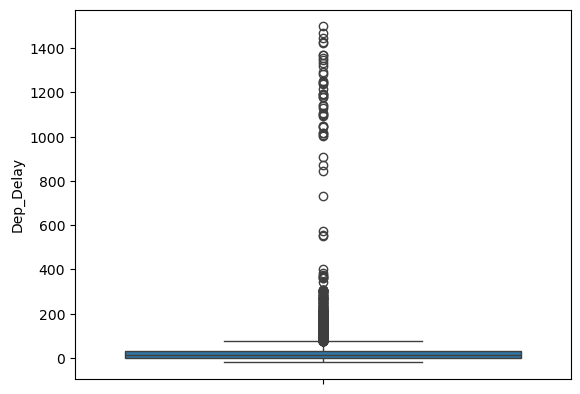

In [12]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.boxplot(y=df["Dep_Delay"])
plt.show()


**Conclusion:**

The boxplot shows several outliers in the Dep_Delay column. Most departure delays are concentrated in the lower range, while some flights have extremely high delays. These outliers indicate that a few flights experienced unusually long departure delays.


In [25]:
df["Dep_Delay"] = df["Dep_Delay"].fillna(df["Dep_Delay"].median())

In [14]:
df["Dep_Delay"].isnull().sum()

np.int64(0)

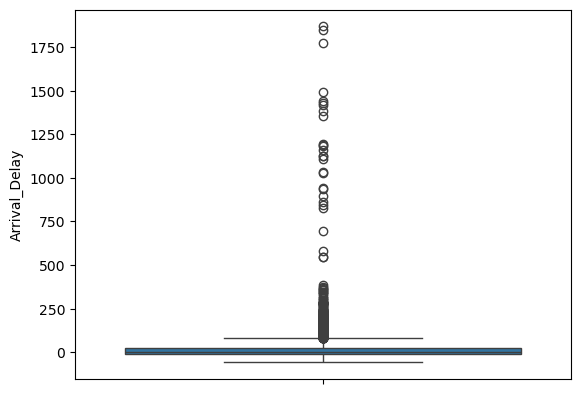

In [15]:
sns.boxplot(y=df["Arrival_Delay"])
plt.show()


**Conclusion:**

The boxplot shows several outliers in the Arrival_Delay column. Most arrival delays are concentrated in the lower range, while a few flights experienced extremely high arrival delays. This indicates the presence of unusual delay values in the dataset.


In [26]:
df["Arrival_Delay"] = df["Arrival_Delay"].fillna(df["Arrival_Delay"].median())

In [27]:
df["Arrival_Delay"].isnull().sum()

np.int64(0)

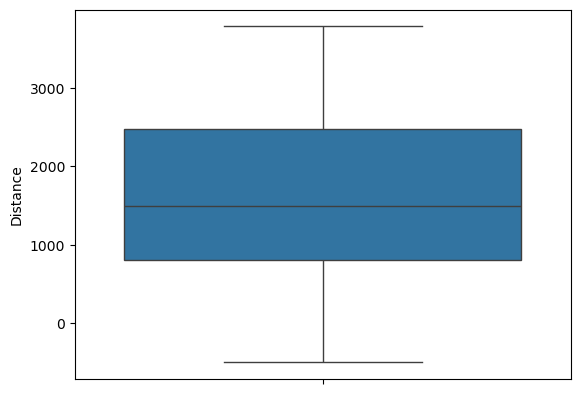

In [28]:
sns.boxplot(y=df["Distance"])
plt.show()


**Conclusion:**

The boxplot shows a wide variation in flight distances, with no clear outliers visible. During data validation, 20 negative distance values were identified as invalid and replaced with the mean after converting them into missing values.


In [29]:
df["Distance"].min()

-497.0

In [30]:
(df["Distance"] < 0).sum()

np.int64(20)

In [32]:
df.loc[df["Distance"] < 0, "Distance"] = float("nan")

df["Distance"] = df["Distance"].fillna(df["Distance"].mean())

In [35]:
df["Distance"].min()

187.0

In [36]:
df["Distance"].isnull().sum()

np.int64(0)

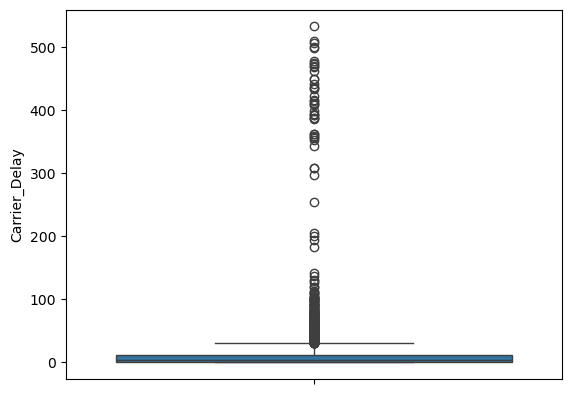

In [21]:
sns.boxplot(y=df["Carrier_Delay"])
plt.show()


**Conclusion:**

The boxplot shows several outliers in the Carrier_Delay column. Most carrier delays are concentrated in the lower range, while a few flights experienced extremely high carrier-related delays. This indicates significant variation in carrier delay times.


In [37]:
df["Carrier_Delay"] = df["Carrier_Delay"].fillna(df["Carrier_Delay"].median())

In [38]:
df["Carrier_Delay"].isnull().sum()

np.int64(0)

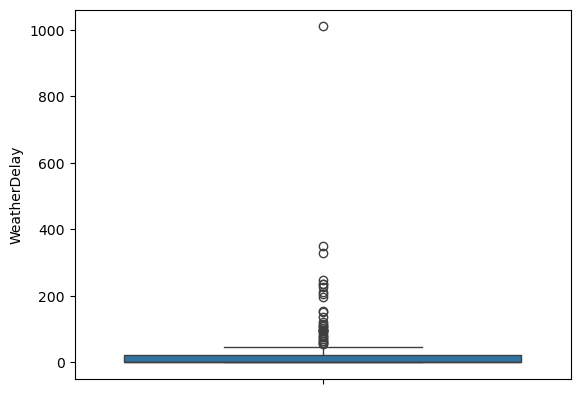

In [40]:
sns.boxplot(y=df["WeatherDelay"])
plt.show()


**Conclusion:**

The boxplot shows several outliers in the WeatherDelay column. Most weather delays are concentrated in the lower range, while a few flights experienced extremely high weather-related delays. One extreme value is above 1,000 minutes, indicating a significant delay due to weather conditions.


In [41]:
df["WeatherDelay"] = df["WeatherDelay"].fillna(df["WeatherDelay"].median())

In [42]:
df["WeatherDelay"].isnull().sum()

np.int64(0)

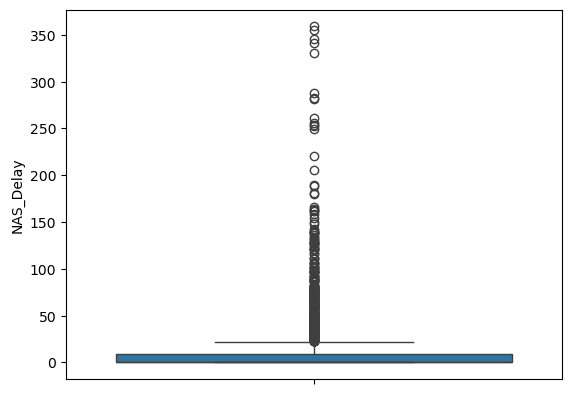

In [43]:
sns.boxplot(y=df["NAS_Delay"])
plt.show()


**Conclusion:**

The boxplot shows several outliers in the NAS_Delay column. Most NAS delays are concentrated in the lower range, while a few flights experienced extremely high delays. Some observations exceed 350 minutes, indicating significant delays related to the National Airspace System.


In [44]:
df["NAS_Delay"] = df["NAS_Delay"].fillna(df["NAS_Delay"].median())

In [45]:
df["NAS_Delay"].isnull().sum()

np.int64(0)

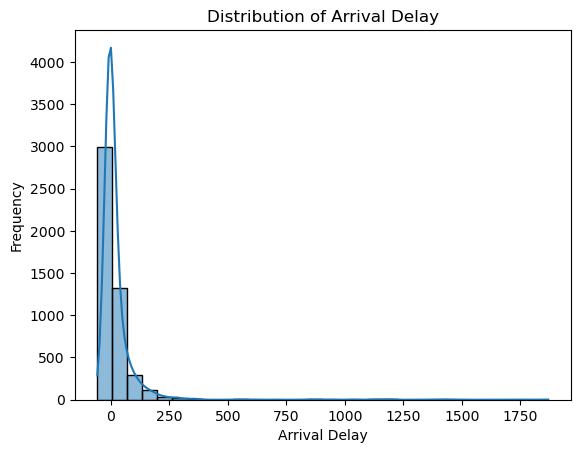

In [46]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.histplot(df["Arrival_Delay"], bins=30, kde=True)
plt.title("Distribution of Arrival Delay")
plt.xlabel("Arrival Delay")
plt.ylabel("Frequency")
plt.show()


**Conclusion:**

The histogram shows a highly right-skewed distribution of Arrival_Delay. Most flights have low or near-zero arrival delays, while a small number of flights experience extremely high delays. The long right tail indicates the presence of extreme delay values in the dataset.



## 5. Correlation Analysis


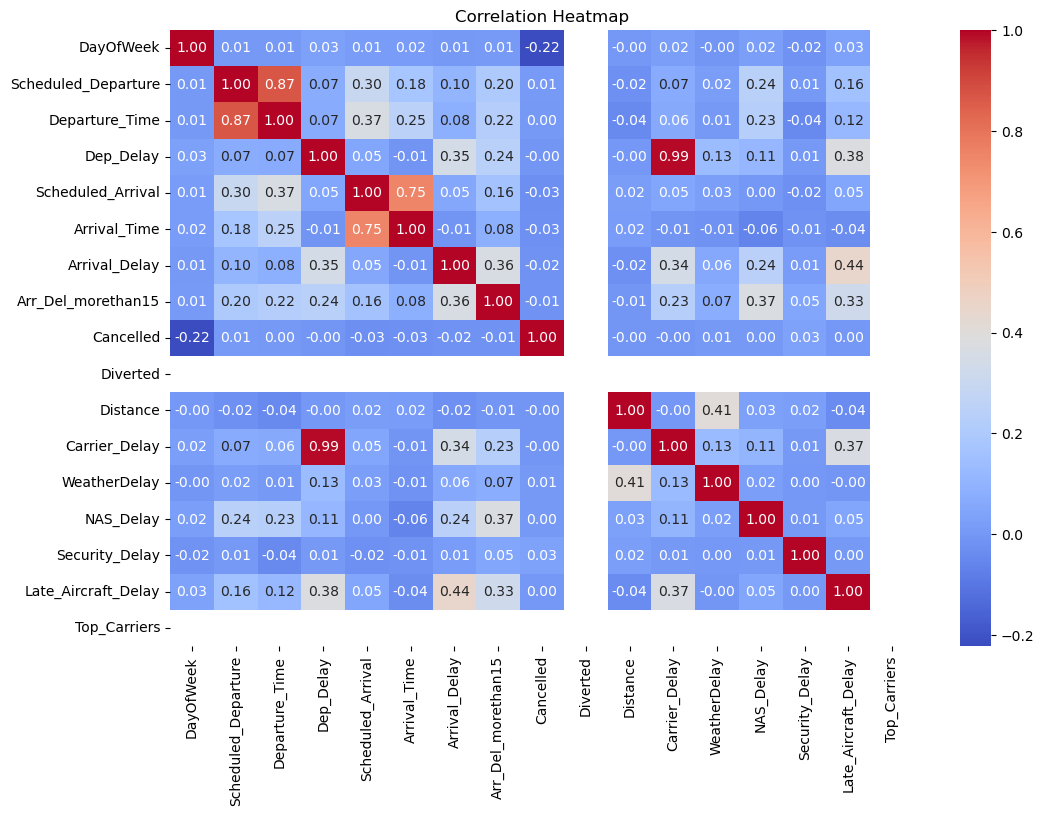

In [49]:
plt.figure(figsize=(12, 8))

correlation = df.corr(numeric_only=True)

sns.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f")

plt.title("Correlation Heatmap")
plt.show()



**Conclusion:**

The correlation heatmap shows a very strong positive correlation (0.99) between Dep_Delay and Carrier_Delay. Arrival_Delay has a positive correlation with Dep_Delay (0.35) and Late_Aircraft_Delay (0.44). These relationships help us understand how different factors are associated with flight delays.


In [6]:
import matplotlib.pyplot as plt
import seaborn as sns


## 6. Day-wise Flight Delay Analysis


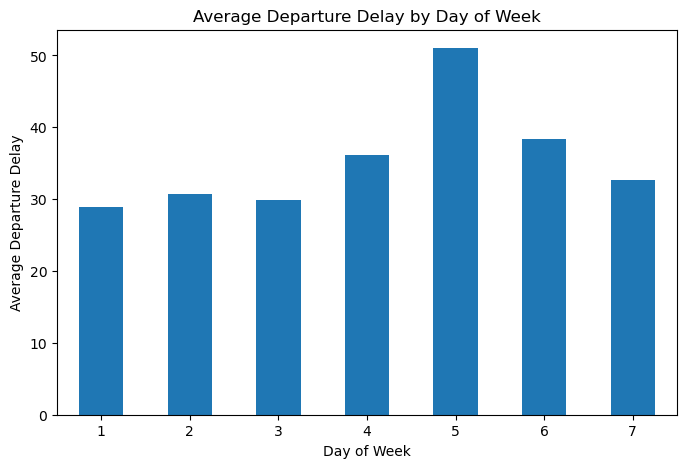

In [7]:
day_delay = df.groupby("DayOfWeek")["Dep_Delay"].mean()

day_delay.plot(kind="bar", figsize=(8, 5))

plt.title("Average Departure Delay by Day of Week")
plt.xlabel("Day of Week")
plt.ylabel("Average Departure Delay")
plt.xticks(rotation=0)
plt.show()



**Conclusion:**

The bar chart shows variations in average departure delay across different days of the week. Day 5 has the highest average departure delay, at approximately 51 minutes, while Day 1 has the lowest, at approximately 29 minutes. This suggests that departure delays vary depending on the day of the week.



## 7. Airport-wise Departure Delay Analysis


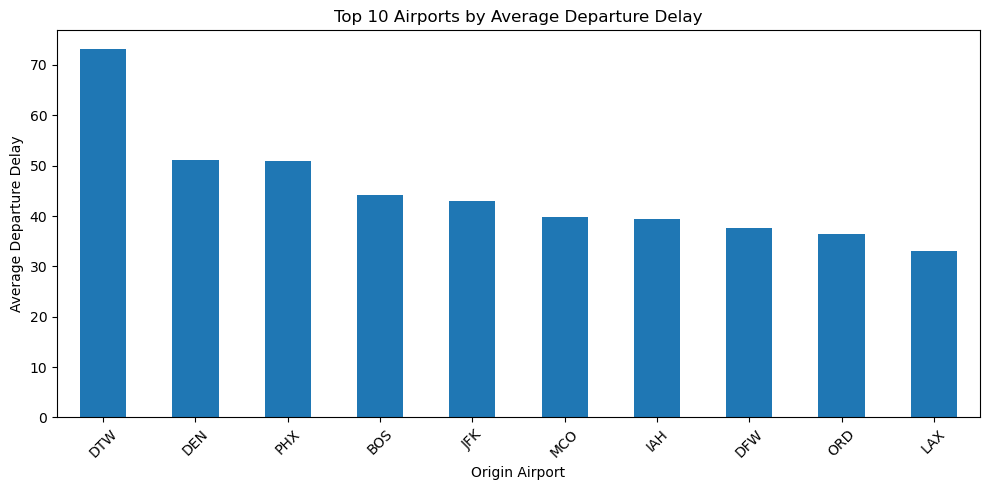

In [9]:
airport_delay = df.groupby("Origin_Airport")["Dep_Delay"].mean().sort_values(ascending=False).head(10)

airport_delay.plot(kind="bar", figsize=(10, 5))

plt.title("Top 10 Airports by Average Departure Delay")
plt.xlabel("Origin Airport")
plt.ylabel("Average Departure Delay")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()



**Conclusion:**

The bar chart shows that average departure delays vary across different origin airports. DTW has the highest average departure delay at approximately 73 minutes, followed by DEN and PHX. LAX has the lowest average delay among the top 10 airports shown. This indicates that departure delays differ across airports.



## 8. Distance vs Arrival Delay Analysis


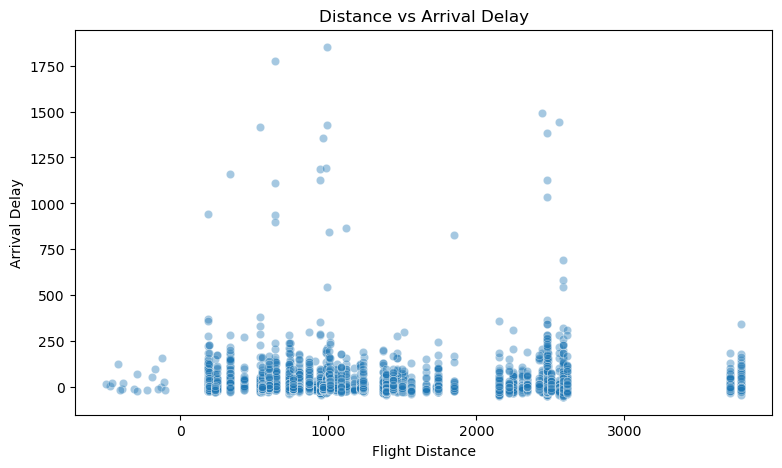

In [10]:
plt.figure(figsize=(9, 5))

sns.scatterplot(data=df, x="Distance", y="Arrival_Delay", alpha=0.4)

plt.title("Distance vs Arrival Delay")
plt.xlabel("Flight Distance")
plt.ylabel("Arrival Delay")
plt.show()



**Conclusion:**

The scatter plot shows no clear linear relationship between flight distance and arrival delay. Most flights experience relatively low arrival delays across different distances. However, a few flights have extremely high arrival delays regardless of their distance.


In [11]:
df["Scheduled_Departure"].head(10)

0    600
1    600
2    600
3    600
4    600
5    600
6    600
7    600
8    600
9    600
Name: Scheduled_Departure, dtype: int64


## 9. Scheduled Departure Time vs Departure Delay


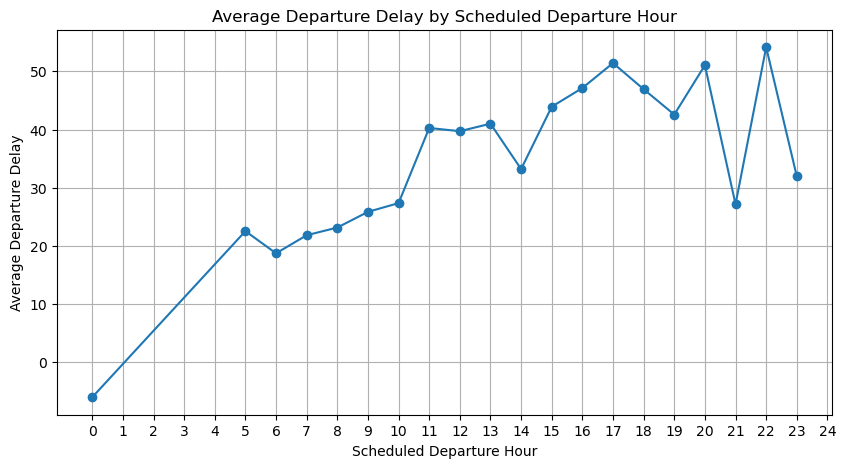

In [12]:
df["Departure_Hour"] = df["Scheduled_Departure"] // 100

hourly_delay = df.groupby("Departure_Hour")["Dep_Delay"].mean()

hourly_delay.plot(kind="line", marker="o", figsize=(10, 5))

plt.title("Average Departure Delay by Scheduled Departure Hour")
plt.xlabel("Scheduled Departure Hour")
plt.ylabel("Average Departure Delay")
plt.xticks(range(0, 25))
plt.grid(True)
plt.show()



**Conclusion:**

The graph shows that average departure delays vary across scheduled departure hours. Higher average delays can be observed during evening and late-night hours, especially around 17:00, 20:00, and 22:00. The lowest average delay is observed at 00:00.

This suggests that departure time may have a relationship with flight delays.



## 10. Flight Delay Cause Analysis


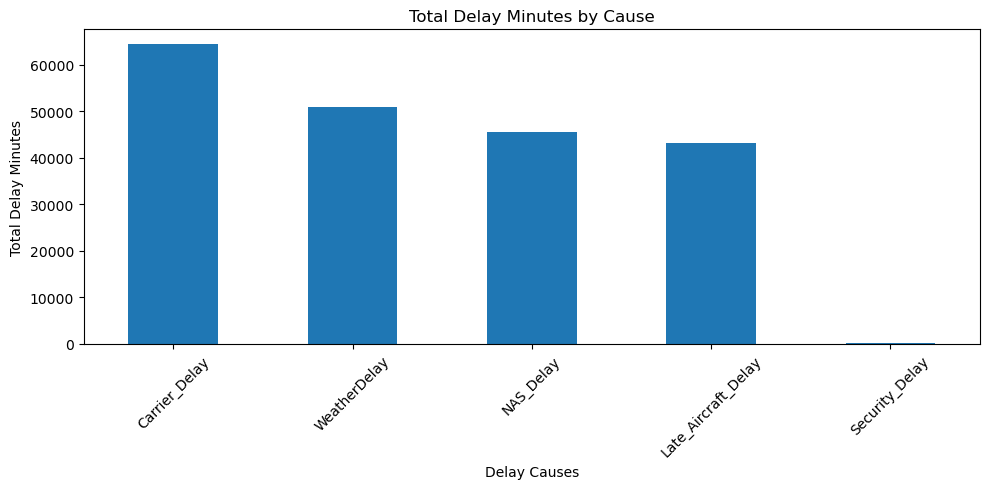

In [13]:
delay_columns = [
    "Carrier_Delay",
    "WeatherDelay",
    "NAS_Delay",
    "Security_Delay",
    "Late_Aircraft_Delay"
]

total_delay = df[delay_columns].sum().sort_values(ascending=False)

total_delay.plot(kind="bar", figsize=(10, 5))

plt.title("Total Delay Minutes by Cause")
plt.xlabel("Delay Causes")
plt.ylabel("Total Delay Minutes")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()



**Conclusion:**

Carrier Delay contributes the highest total delay minutes, followed by Weather Delay and NAS Delay. Late Aircraft Delay also accounts for a significant amount of delay time, while Security Delay has a very small contribution.

This analysis indicates that carrier-related issues are the largest contributor to total delay minutes in this dataset.



## 11. Flight Cancellation and Diversion Analysis


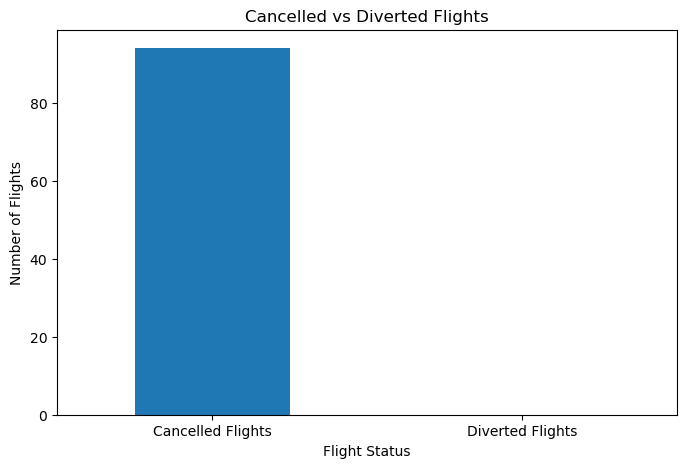

In [14]:
flight_status = pd.Series({
    "Cancelled Flights": df["Cancelled"].sum(),
    "Diverted Flights": df["Diverted"].sum()
})

flight_status.plot(kind="bar", figsize=(8, 5))

plt.title("Cancelled vs Diverted Flights")
plt.xlabel("Flight Status")
plt.ylabel("Number of Flights")
plt.xticks(rotation=0)
plt.show()



**Conclusion:**

The graph shows that approximately 94 flights were cancelled, while no diverted flights were recorded in the dataset.

This indicates that flight cancellations occurred more frequently than diversions in the given dataset.



## 12. Departure Delay vs Arrival Delay Analysis


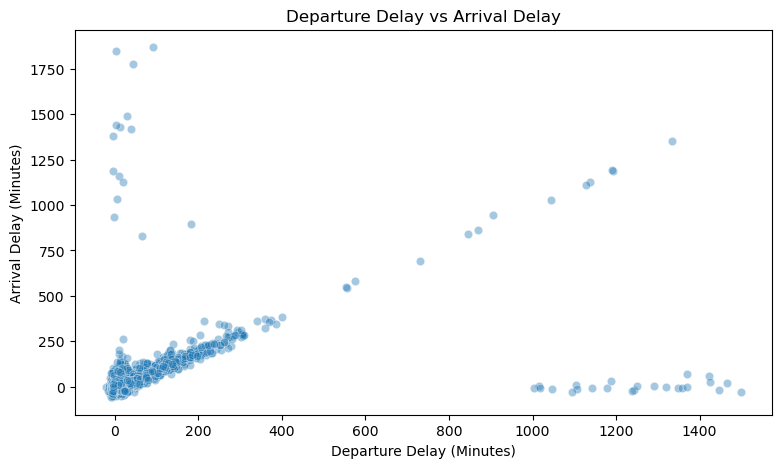

In [15]:
plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=df,
    x="Dep_Delay",
    y="Arrival_Delay",
    alpha=0.4
)

plt.title("Departure Delay vs Arrival Delay")
plt.xlabel("Departure Delay (Minutes)")
plt.ylabel("Arrival Delay (Minutes)")
plt.show()



**Conclusion:**

The scatter plot shows a positive relationship between Departure Delay and Arrival Delay. Most flights follow a similar pattern, where an increase in departure delay is generally associated with an increase in arrival delay.

However, some flights show unusually high delays and a few flights recover time before arrival. This suggests that departure delays can affect arrival times, but the relationship is not identical for every flight.



## 13. Day-wise Arrival Delay Analysis


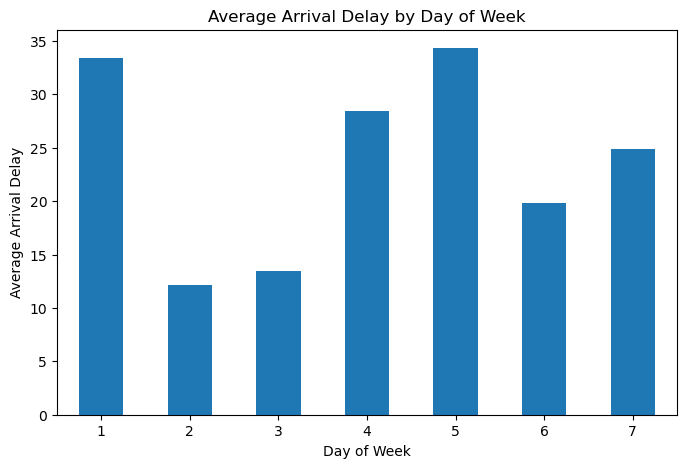

In [16]:
arrival_day_delay = df.groupby("DayOfWeek")["Arrival_Delay"].mean()

arrival_day_delay.plot(kind="bar", figsize=(8, 5))

plt.title("Average Arrival Delay by Day of Week")
plt.xlabel("Day of Week")
plt.ylabel("Average Arrival Delay")
plt.xticks(rotation=0)
plt.show()



**Conclusion:**

The graph shows that average arrival delays vary across different days of the week. Day 5 has the highest average arrival delay, followed by Day 1. Day 2 has the lowest average arrival delay.

This suggests that arrival delay patterns differ depending on the day of the week.


## 14. Departure Delay Distribution

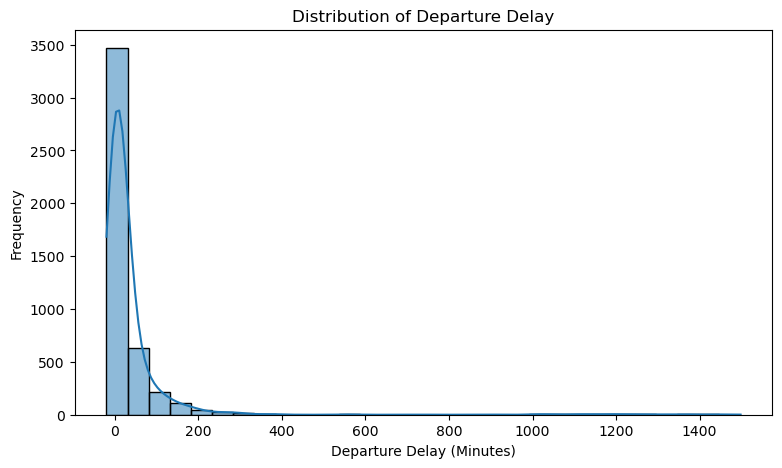

In [17]:
plt.figure(figsize=(9, 5))

sns.histplot(data=df, x="Dep_Delay", bins=30, kde=True)

plt.title("Distribution of Departure Delay")
plt.xlabel("Departure Delay (Minutes)")
plt.ylabel("Frequency")
plt.show()



### Conclusion:
The distribution of departure delay is highly right-skewed. Most flights have relatively low departure delays, while a small number of flights experience very high delays. The long tail on the right side indicates the presence of extreme delay values.


# 15. Final Conclusion

## Key Findings

1. **Departure Delays:** Most flights experience relatively low departure delays, but a few flights have extremely high delays.

2. **Arrival Delays:** Arrival delay distribution is also right-skewed, indicating that most flights have smaller delays while some experience significant delays.

3. **Delay by Day of Week:** Average departure and arrival delays vary across different days. Day 5 shows comparatively high average delays in the analyzed data.

4. **Airport Analysis:** DTW has the highest average departure delay among the top 10 airports shown in the analysis.

5. **Scheduled Departure Time:** Departure delays vary by scheduled departure hour, with some evening hours showing higher average delays.

6. **Distance vs Arrival Delay:** The scatter plot does not show a clear relationship between flight distance and arrival delay.

7. **Delay Causes:** Carrier Delay contributes the highest total delay minutes, followed by Weather Delay, NAS Delay, and Late Aircraft Delay.

8. **Cancellation and Diversion:** The analysis shows cancelled flights, while diverted flights are very few or absent in the displayed comparison.

9. **Correlation Analysis:** Departure Delay has a very strong positive correlation with Carrier Delay in the analyzed dataset.

## Overall Conclusion

This Exploratory Data Analysis helped identify important patterns in flight delays, including variations by day, airport, scheduled departure time, and delay causes.

The analysis indicates that Carrier Delay is a major contributor to total delay minutes. It also highlights the presence of extreme delays and differences in average delays across airports and days.

Overall, this project demonstrates how Python libraries such as Pandas, Matplotlib, Seaborn, and NumPy can be used to clean data, explore patterns, visualize insights, and draw meaningful conclusions from flight data.
